# This is the cell calling script - it filters for single cells and filters out ambient barcodes. It also collapses the expression of multiple probes per gene to an expression per gene based on the max probe expression per gene. 

In [1]:
import os
import gzip
import time
import numpy as np

import h5py
import scipy.sparse as sparse
import scipy.io as sio
import scipy.stats as stats

In [2]:
dataset = h5py.File('.h5','r') # call the h5 file here in 'the name of the h5 file.h5'
mtx = dataset['matrix']
mtx.keys()

<KeysViewHDF5 ['barcodes', 'data', 'features', 'indices', 'indptr', 'shape']>

In [3]:
gene_dict={}
for i,idd in enumerate(np.char.decode(np.array(mtx['features']['id']))):
    ## idd example = 'AD4700001_03243_3' aka organism_gene_probe
    gene = "_".join(idd.split("_")[0:-1])
    #features_dict[i] = idd
    if gene in gene_dict.keys():
        pass
    else:
        gene_dict[gene]=[]
    
print(i,'probes') # 11723 probes
print(len(gene_dict),'genes') #3189 genes
print(round(i/len(gene_dict),0),'avg. probes per gene') # avg probes per gene

11722 probes
3189 genes
4.0 avg. probes per gene


Cell calling script to limit cells to single cells and filtering out ambient barcodes. 

In [4]:
print("Indices: {}".format(mtx['indices']))
print("Indptr: {}".format(mtx['indptr']))
print("Shape: {}".format(mtx['shape']))
print("Data: {}".format(mtx['data']))
print("Barcode: {}".format(mtx['barcodes']))
print("Feature: {}".format(mtx['features']['id']))

gene_dict={}
for i,idd in enumerate(np.char.decode(np.array(mtx['features']['id']))):
    gene = "_".join(idd.split("_")[0:-1])
    #features_dict[i] = idd
    if gene in gene_dict.keys():
        pass
    else:
        gene_dict[gene]=[]

with gzip.open('features.tsv.gz','wt') as f:
    for gene in gene_dict:
        f.write("\t".join([gene,gene,'Gene Expression'])+"\n")

i = mtx['indices']
indices = np.array(i)
print('indices',indices) #5,523,299 entries in this array corresponding to all the non-zero UMI values, each entry represents the row i.e. gene i.e. feature to which the UMI value in the data array corresponds to

d = mtx['indptr']
indptr = np.array(d) #6,794,880 size array where each value represents the index in data/indices at which a new cell is specified since the UMI vals are listed in descending order of gene/feature then barcode/cell
print('indptr',indptr)

s = mtx['shape']
shape = np.array(s)
print('matrix shape',shape)
    
x = mtx['data']
y = mtx['features']['id']
z = mtx['barcodes']

data = np.array(x)
print('data len',len(data))
features = np.char.decode(np.array(y))
print('features len',len(features))
barcodes = np.char.decode(np.array(z))
print('barcodes len',len(barcodes))

print('gene len',len(gene_dict))


print('\n-----start-------\n')

with gzip.open('barcodes.tsv.gz','wt') as f:
    for b in barcodes:
        f.write(b+"\n")
        
        
start = 0
mark=time.time()
result_matrix = []
valid_barcodes=[]
for c in range(1,len(indptr)-1): #for each cell
    vals = []
    if c%100000==0:
        print(c,'cells parsed')
        print(time.time()-mark,'s')
        mark = time.time()
    probes = [features[p] for p in indices[start:indptr[c]]]
    UMIs = data[start:indptr[c]]

    if np.sum(UMIs)<5: # to reduce compute, ignore barcodes with less than five assigned reads/umis. You can change this anywhere from 2-10 i'd say 
        pass
    else:
        valid_barcodes.append(barcodes[c-1]) # save barcode for cells that are collected
    
        cell_dict={}
        for z in zip(probes,UMIs):
            gene = "_".join(z[0].split("_")[0:-1])
            if gene in cell_dict:
                cell_dict[gene].append(z[1])

            else:
                cell_dict[gene]=[z[1]]

        for k,key in enumerate(gene_dict): #k is index of genes i.e. rows of matrix, cell index = c-1 i.e. columns of matrix
            try:

                val = np.max(cell_dict[key]) #TAKES MAX() FROM LIST OF ALL PROBE UMI COUNTS FOR GIVEN GENE

            except KeyError:

                val = 0
                
            vals.append(val)
               
        result_matrix.append(vals)
        
    start = indptr[c]

print(np.shape(result_matrix))

#might take 5-10 minutes to run

Indices: <HDF5 dataset "indices": shape (5523299,), type "<i8">
Indptr: <HDF5 dataset "indptr": shape (6794881,), type "<i8">
Shape: <HDF5 dataset "shape": shape (2,), type "<i4">
Data: <HDF5 dataset "data": shape (5523299,), type "<i4">
Barcode: <HDF5 dataset "barcodes": shape (6794880,), type "|S24">
Feature: <HDF5 dataset "id": shape (11723,), type "|S256">
indices [1294   15 1206 ... 1334 6912 1918]
indptr [      0       0       0 ... 5523299 5523299 5523299]
matrix shape [  11723 6794880]
data len 5523299
features len 11723
barcodes len 6794880
gene len 3189

-----start-------

100000 cells parsed
2.449708938598633 s
200000 cells parsed
2.4690937995910645 s
300000 cells parsed
2.478578805923462 s
400000 cells parsed
2.598706007003784 s
500000 cells parsed
2.4141812324523926 s
600000 cells parsed
2.5747478008270264 s
700000 cells parsed
2.5257370471954346 s
800000 cells parsed
2.59184193611145 s
900000 cells parsed
2.6665360927581787 s
1000000 cells parsed
7.819738149642944 s
11000

In [5]:
import matplotlib.pyplot as plt
import scipy

import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

/Users/ryanmcnulty/opt/anaconda3/lib/python3.8/site-packages/statsmodels/tsa/base/tsa_model.py:7: FutureWarning: pandas.Float64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import (
/Users/ryanmcnulty/opt/anaconda3/lib/python3.8/site-packages/statsmodels/tsa/base/tsa_model.py:7: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import (


In [6]:
# create list of barcodes and their UMI totals then sort list by total UMIs in descending order

UMI_sums = []
for i,x in enumerate(result_matrix): # for all collected barcodes
    UMI_sums.append([i,np.sum(x),valid_barcodes[i]]) # create entry in list whichg stored barcode index, total UMI count, and barcode itself 
    
UMI_sums.sort(key = lambda x: x[1],reverse=True) # sort list by total UMIs

In the next part U and T will need to be adjusted to call cells properly. BAsed on U and T, the red and green lines will be in different places. 

In [7]:

U = 1E4 # UMI cutoff for designating real cells, arbitrarily set by user based on the dataset, as a general rule of thumb should set so it incorporates the first ~100 cells
T = 2E2 # UMI cutoff for designating ambient barcodes, arbitarily set by user based on the dataset, should be set near the knee of the below plot and/or at a point past where it intersects with the # of cells targeted/loaded in the expt


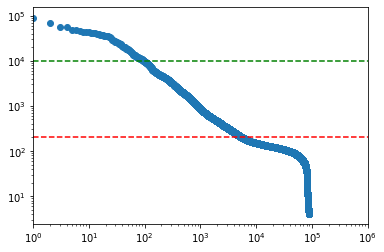

In [8]:
#create barcode rank vs total UMIs plot on sorted data

xs = np.logspace(0, 6, num=6)

plt.figure()
plt.scatter(np.arange(0,len(UMI_sums),1),[x[1] for x in UMI_sums])
plt.plot(xs,[U]*len(xs),'g--')
plt.plot(xs,[T]*len(xs),'r--')
plt.yscale('log')
plt.xscale('log')
plt.xlim([1,1E6])
plt.show()

In [9]:
#create a list of sorted indices (where indices correspond to the current order of the result_matrix)

sorted_cell_indices = [x[0] for x in UMI_sums]
sorted_barcodes = [x[2] for x in UMI_sums]
sorted_UMI_totals = [x[1] for x in UMI_sums]
print(np.shape(sorted_cell_indices))
print(np.shape(sorted_barcodes))

(87487,)
(87487,)


In [10]:
# testing out things

print(UMI_sums[0]) # print out first entry of sorted list
print(np.sum(result_matrix[UMI_sums[0][0]])) #testing the index
print(list(barcodes).index(UMI_sums[0][2])) # to test for presence of barcode in original dataset


#all tests passed

[73429, 95656, 'TCTACATGTCATTGCA-1']
95656
5716010


In [11]:
#now actually sort the dense matrix 

result_matrix_sorted = np.array(result_matrix)[sorted_cell_indices]

In [12]:
print(np.shape(result_matrix_sorted))

(87487, 3189)


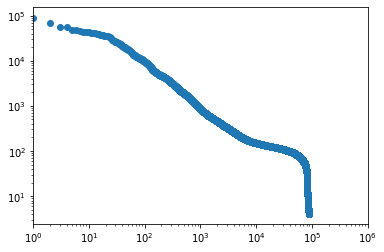

In [13]:
#test if sorting worked on results_matrix

collector = []
for cell in result_matrix_sorted:
    collector.append(np.sum(cell))
    
plt.figure()
plt.scatter(np.arange(0,len(collector)),collector)
plt.xscale('log')
plt.yscale('log')
plt.xlim([1,1E6])
plt.show()

# cool, cell matrix now sorted

In [14]:
#another test to visualize first ten entries and last 10 entries of sorted matrix as well as the length of each cell array and the total UMIs

for c in range(0,10,1):
    print(result_matrix_sorted[c],len(result_matrix_sorted[c]),np.sum(result_matrix_sorted[c]))
print('\n')
for c in range(10,0,-1):
    print(result_matrix_sorted[-c],len(result_matrix_sorted[-c]),np.sum(result_matrix_sorted[-c]))
    
#bug note: idk why barcodes with sums=2 are still included when I specified np.sum(UMIs) < 3 should be excluded earlier but oh well.. it seems like its 1 off from intended for whatever reasons so if you set < 2 you'll remove barcodes with < 1 total UMIs

[ 1  7  5 ...  0  0 36] 3189 95656
[ 1  7  0 ...  1  0 31] 3189 90132
[ 0  2  0 ...  0  0 29] 3189 69387
[ 0  4  0 ...  0  0 11] 3189 55064
[ 2  9  0 ...  0  2 30] 3189 54939
[ 3  4  0 ...  0  1 13] 3189 47729
[ 0  2  0 ...  3  0 10] 3189 47152
[ 0  0  3 ...  3  0 14] 3189 46242
[ 0  2  1 ...  4  0 11] 3189 43464
[0 1 3 ... 0 0 5] 3189 42608


[0 0 0 ... 0 0 0] 3189 4
[0 0 0 ... 0 0 0] 3189 4
[0 0 0 ... 0 0 0] 3189 4
[0 0 0 ... 0 0 0] 3189 4
[0 0 0 ... 0 0 0] 3189 4
[0 0 0 ... 0 0 0] 3189 4
[0 0 0 ... 0 0 0] 3189 4
[0 0 0 ... 0 0 0] 3189 4
[0 0 0 ... 0 0 0] 3189 4
[0 0 0 ... 0 0 0] 3189 4


In [15]:
# now get cell indexes for "U" and "T" thresholds 

for c,cell in enumerate(result_matrix_sorted):
    if np.sum(cell)>U:
        pass
    else:
        U_index = c-1
        break
    

for c,cell in enumerate(result_matrix_sorted):
    if np.sum(cell)<T:
        T_index = c
        break
    
print(U_index,T_index)

94 5561


In [16]:
gene_count = result_matrix_sorted # sorted cell x gene matrix of collapsed UMI values
print(np.shape(gene_count)) 

(87487, 3189)


In [17]:
print(np.shape(gene_count.sum(axis=1))) # okay so sum(axis=1) means for each row (cell) sum along the columns (genes)
print(gene_count.sum(axis=1))

(87487,)
[95656 90132 69387 ...     4     4     4]


In [18]:
 # filter genes without count (in ambient barcodes)
ambient_count = gene_count[T_index:,] #select all barcodes which satisfy T threshold (<1E2 UMIs total)
print(np.shape(ambient_count))

total_gene_count_ambient = ambient_count.sum(axis=0) # for each gene, sum all the counts detected across all cells
print(np.shape(total_gene_count_ambient))
print(total_gene_count_ambient)

nonzero_ind = np.flatnonzero(total_gene_count_ambient) # remove genes which have no counts across all ambient barcodes
print(np.shape(nonzero_ind))
print(nonzero_ind) # this is a list of all the indexes (genes) that do not sum up to zero in the ambient subset i.e. genes actually detected in ambient

(81926, 3189)
(3189,)
[ 253 4992  164 ...  639  807 2298]
(3148,)
[   0    1    2 ... 3186 3187 3188]


In [19]:
# break gene_count matrix into the three count matrices, excluding columns (genes) not found in ambient barcode subset
real_count = gene_count[:U_index, nonzero_ind]
putative_count = gene_count[U_index:T_index, nonzero_ind]
print(np.shape(putative_count)) # the matrix of putative cells that we need to test 
putative_barcodes = sorted_barcodes[U_index:T_index]
print(len(putative_barcodes))
ambient_count = gene_count[T_index:, nonzero_ind] 

# get normalized count matrix 
ambient_freq = ambient_count / ambient_count.sum(axis=1, keepdims=True)  #for each barcode, divide gene counts by total UMIs to get frequency                                                      

(5467, 3148)
5467


In [20]:

ambient_mean = ambient_freq.mean(axis=0) # average frequency of each gene across ambient barcodes
ambient_var = ambient_freq.var(axis=0) # variances of frequency for each gene 

print(np.shape(ambient_mean))
print(np.shape(ambient_var))

res = sm.OLS(ambient_var, ambient_mean).fit() # linearly regress relationship b/w mean and var
slope = res.params.item()
print(slope)

lower_cutoff = int(np.ceil(1/slope))
print(lower_cutoff)

(3148,)
(3148,)
0.04154321833758532
25


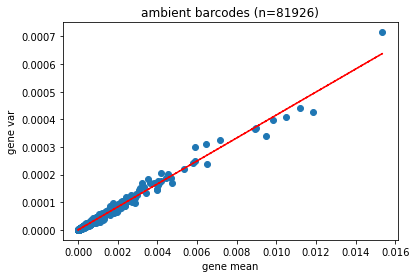

In [21]:
plt.figure()
plt.title('ambient barcodes (n='+str(len(ambient_count))+')')
plt.scatter(ambient_mean,ambient_var)
plt.plot(ambient_mean,ambient_mean*slope,'r--')
plt.xlabel('gene mean')
plt.ylabel('gene var')
plt.show()

In [22]:
'''Both real and putative counts should have per-barcode total count greater than lower_cutoff'''
# real_ind_to_keep = np.flatnonzero(real_count.sum(axis=1) > lower_cutoff)
# real_count = real_count[real_ind_to_keep]
# putative_ind_to_keep = np.flatnonzero(putative_count.sum(axis=1) > lower_cutoff)
# putative_count = putative_count[putative_ind_to_keep]


ambient_ind_to_keep = np.flatnonzero(ambient_count.sum(axis=1) > lower_cutoff) # determine ambient barcodes with total UMIs > lower cutoff which is 1/slope
ambient_count = ambient_count[ambient_ind_to_keep] # slice ambient matrix to only keep the barcodes satisfying the above criteria
print(np.shape(ambient_count)) # print final shape of matrix to see how many barcodes were kept

(75693, 3148)


In [23]:
# performing the actual statistical test to distinguish real cells from ambient background

def collect_pvalues(count_matrix, prior_p, slope, num_sim=1000):
    pvals_total = []
    mark=time.time()
    for b,barcode in enumerate(count_matrix): # order maintained

        if b%100==0 and b!=0: # adding a few lines to track progress
            print(b,time.time()-mark,'s')
            mark=time.time()

        total_count = barcode.sum()

        mean = prior_p * total_count #multiply the average ambient frequency of each gene by total UMIs of barcode in question to get a expected # UMIs if barcode is indeed ambient noise
        var = (prior_p * slope) * (total_count ** 2) # get predicted variance of each gene if indeed ambient

        phi = mean**2 / (var - mean)
        p = mean / var

        Lb = scipy.stats.nbinom.logpmf(barcode, phi, p).sum()

        # monte carlo with ambient null based on negative binomial
        samples = scipy.stats.nbinom.rvs(phi, p, size=(num_sim, len(prior_p)))
        Lsamples = scipy.stats.nbinom.logpmf(samples, phi, p).sum(axis=1)
        pval = (np.count_nonzero(Lsamples < Lb) + 1) / (num_sim + 1)
        pvals_total.append(pval)   

    return np.array(pvals_total)

In [24]:
# putative_pvals = collect_pvalues(putative_count, ambient_mean, slope)
putative_pvals = collect_pvalues(putative_count, ambient_mean, slope)

100 46.9576358795166 s
200 46.56624984741211 s
300 45.71708703041077 s
400 43.740880727767944 s
500 44.893555879592896 s
600 43.92623782157898 s
700 43.89890813827515 s
800 42.09037470817566 s
900 40.85602593421936 s
1000 40.11885905265808 s
1100 42.08943009376526 s
1200 43.50327396392822 s
1300 41.79249119758606 s
1400 41.24205923080444 s
1500 39.732762813568115 s
1600 39.04983878135681 s
1700 39.817281007766724 s
1800 39.52665996551514 s
1900 39.782480239868164 s
2000 39.91551208496094 s
2100 38.92770791053772 s
2200 39.050193309783936 s
2300 39.69654202461243 s
2400 39.10530686378479 s
2500 40.04855799674988 s
2600 39.38410210609436 s
2700 42.00523495674133 s
2800 41.13635325431824 s
2900 40.18382120132446 s
3000 41.04042720794678 s
3100 40.83934307098389 s
3200 40.93311405181885 s
3300 41.07136058807373 s
3400 41.06943988800049 s
3500 40.78598594665527 s
3600 39.77712416648865 s
3700 40.9639732837677 s
3800 40.215113162994385 s
3900 42.56710600852966 s
4000 40.85687804222107 s
4100

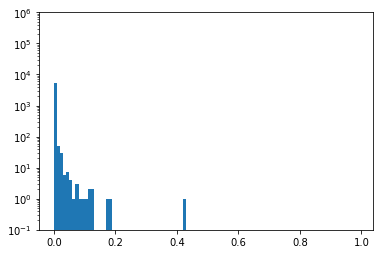

In [25]:
plt.figure()
plt.hist(putative_pvals,bins=np.arange(0,1,0.01))
plt.yscale('log')
plt.ylim([1E-1,1E6])
plt.show()

1085 (False, 0.003170397713741367) TCAGTCCCAATTTCGG-1 715
2115 (False, 0.002149788805958851) AAACGAATCTCAAAGC-1 418
2506 (False, 0.003170397713741367) ACAGCCGAGGGAGTTC-1 366
2626 (False, 0.002149788805958851) GTCCCATCACATTACG-1 352
2655 (False, 0.05110797459421313) CCCTAACAGACAGCGT-1 349
2729 (False, 0.002149788805958851) GTAGAGGAGAGCTTTC-1 342
2737 (False, 0.002149788805958851) CGAAGGATCACGGACC-1 341
2803 (False, 0.002149788805958851) GGAGATGCACTACCGG-1 336
2821 (False, 0.002149788805958851) CAGAGCCGTAGGCAGT-1 334
2847 (False, 0.028147078395559896) TTGCGTCCAACGGTAG-1 333
3032 (False, 0.002149788805958851) CGTCAAATCTCCTACG-1 318
3120 (False, 0.006199249105037981) TCCGATCAGTCGAAAT-1 311
3149 (False, 0.002149788805958851) ATCGCCTTCTTCGTGC-1 308
3173 (False, 0.002149788805958851) TTCTGTACAGCCTACG-1 307
3191 (False, 0.003170397713741367) CCTCCAAGTACCAATC-1 305
3196 (False, 0.06009394969600361) GTAAGTCCAATCCTAG-1 305
3202 (False, 0.002149788805958851) AGACCATCATGCGGTC-1 304
3208 (False, 0.0

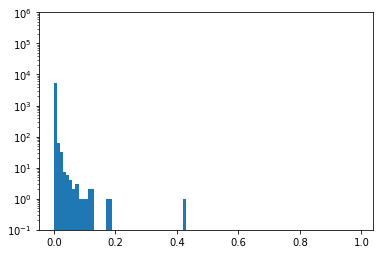

In [30]:
'''trt setting this error rate, alpha, as low as possible (e.g., 0.002)'''
putative_reject, putative_pvals_corrected = multipletests(putative_pvals, alpha=0.002, method='fdr_bh')[:2]  #corrected pvals returned in original order

cell_indexes_to_keep = [i for i,x in enumerate(real_count)]
i_i = len(cell_indexes_to_keep)
for i,x in enumerate(zip(putative_reject,putative_pvals_corrected)):
    if x[0]==False:
        print(i,x,putative_barcodes[i],np.sum(result_matrix[valid_barcodes.index(putative_barcodes[i])])) # printing out information about barcodes that failed test
    else:
        cell_indexes_to_keep.append(i+i_i)
    
plt.figure()
plt.hist(putative_pvals_corrected,bins=np.arange(0,1,0.01))
plt.yscale('log')
plt.ylim([1E-1,1E6])
plt.show()

gene_count_called = np.vstack((real_count, putative_count[putative_reject])) # concatenating two matrices to return the final gene count matrix of all "valid" cells

In [31]:
print(gene_count_called)

[[ 1  7  5 ...  0  0 36]
 [ 1  7  0 ...  1  0 31]
 [ 0  2  0 ...  0  0 29]
 ...
 [ 0  0  0 ...  0  0  0]
 [ 0  0  0 ...  0  0  0]
 [ 0  0  0 ...  0  0  0]]


In [41]:
#checking vals

print(np.shape(gene_count_called))
print(len(real_count),len(putative_count),len(real_count)+len(putative_count))
print(len(cell_indexes_to_keep))

print("______\n")

print(len(sorted_barcodes))
final_barcodes = np.array(sorted_barcodes)[cell_indexes_to_keep]
print(len(final_barcodes))
      
print("_______\n")
    
final_genes = []
ordered_genes = [k for k in gene_dict.keys()]
for i,g in enumerate(ordered_genes): 
    if i in nonzero_ind:
        final_genes.append(g)

print(len(ordered_genes))
print(len(final_genes))


(4966, 3148)
94 5467 5561
4966
______

87487
4966
_______

3189
3148


In [49]:
print(final_barcodes)

['TCTACATGTCATTGCA-1' 'GCGGAAAGTAACTGCT-1' 'CTGTGAAAGGCGTTGA-1' ...
 'TGACTCCTCCCTTGGT-1' 'TGGTTAGTCATTCATC-1' 'TGTCAGAAGTGCAAAT-1']


In [50]:
print(len(final_barcodes))

4966


# okay have all the barcodes for valid cells now return to original h5 script ... reusing the raw input final but keeping only the barcodes that passed the test

In [45]:
dataset = h5py.File('.h5','r') # your h5 file
mtx = dataset['matrix']
mtx.keys()

<KeysViewHDF5 ['barcodes', 'data', 'features', 'indices', 'indptr', 'shape']>

The next part creates the matrix.mtx file. This file will need to be gzipped before it can be used for the scanpy analyses. The matrix.mtx.gz file shoud be in the same folder as the features.tsv.gz and the barcode.tsv.gz files created above. The scanpy analyses script will read all three files to create the adata file. 

In [57]:
print("Indices: {}".format(mtx['indices']))
print("Indptr: {}".format(mtx['indptr']))
print("Shape: {}".format(mtx['shape']))
print("Data: {}".format(mtx['data']))
print("Barcode: {}".format(mtx['barcodes']))
print("Feature: {}".format(mtx['features']['id']))

gene_dict={}
for i,idd in enumerate(np.char.decode(np.array(mtx['features']['id']))):
    gene = "_".join(idd.split("_")[0:-1])
    #features_dict[i] = idd
    if gene in gene_dict.keys():
        pass
    else:
        gene_dict[gene]=[]
        
print(len(gene_dict))

with gzip.open('features.tsv.gz','wt') as f:
    for gene in gene_dict:
        f.write("\t".join([gene,gene,'Gene Expression'])+"\n")

i = mtx['indices']
indices = np.array(i)
print('indices',indices) #6,857,036 entries in this array corresponding to all the non-zero UMI values, each entry represents the row i.e. gene i.e. feature to which the UMI value in the data array corresponds to

d = mtx['indptr']
indptr = np.array(d) #6,943 value array where each value represents the index in data/indices at which a new cell is specified since the UMI vals are listed in descending order of gene/feature then barcode/cell
print('indptr',indptr)

s = mtx['shape']
shape = np.array(s)
print('matrix shape',shape)
    
x = mtx['data']
y = mtx['features']['id']
z = mtx['barcodes']

data = np.array(x)
print('data len',len(data))
features = np.char.decode(np.array(y))
print('features len',len(features))
barcodes = np.char.decode(np.array(z))
print('barcodes len',len(barcodes))

print('gene len',len(gene_dict))


print('\n-----start-------\n')

with gzip.open('barcodes.tsv.gz','wt') as f:
    for b in barcodes:
        if b in final_barcodes:
            f.write(b+"\n")
        
start = 0
row,col,val=([],[],[])
mark=time.time()
true_count=0
for c in range(1,len(indptr)-1): #for each cell
    if c%100000==0:
        print(c,'cells parsed')
        print(time.time()-mark,'s')
        mark = time.time()
        
        
    if barcodes[c-1] in final_barcodes:
    
        probes = [features[p] for p in indices[start:indptr[c]]]
        UMIs = data[start:indptr[c]]
        #print(probes)
        #print(UMIs)

        cell_dict={}
        #for gene in gene_dict:
        #    cell_dict[gene]=[]
        for z in zip(probes,UMIs):
            gene = "_".join(z[0].split("_")[0:-1])
            if gene in cell_dict:
                cell_dict[gene].append(z[1])

            else:
                cell_dict[gene]=[z[1]]

        for k,key in enumerate(gene_dict): #k is index of genes i.e. rows of matrix, cell index = c-1 i.e. columns of matrix
            try:
                if len(cell_dict[key])>0:
                #print(k,key,cell_dict[key])
                    row.append(k)
                    col.append(true_count)
                    val.append(np.max(cell_dict[key])) #TAKES MAX() FROM LIST OF ALL PROBE UMI COUNTS FOR GIVEN GENE
                    #val.append(np.mean(cell_dict[key]))
                    #val.append(np.median(cell_dict[key]))
            except KeyError:
                pass
            
        true_count+=1

    start = indptr[c]
    #if c==5:
    #    break

# creating sparse matrix
sparseMatrix = sparse.csr_matrix((val, (row, col)), 
                          shape = (len(gene_dict), len(final_barcodes)))#.toarray()

sio.mmwrite("matrix.mtx",sparseMatrix) #this is the matrix.mtx file that you will need to gzip and then use for the scanpy analyses
print('\n-----done-------\n')


Indices: <HDF5 dataset "indices": shape (5523299,), type "<i8">
Indptr: <HDF5 dataset "indptr": shape (6794881,), type "<i8">
Shape: <HDF5 dataset "shape": shape (2,), type "<i4">
Data: <HDF5 dataset "data": shape (5523299,), type "<i4">
Barcode: <HDF5 dataset "barcodes": shape (6794880,), type "|S24">
Feature: <HDF5 dataset "id": shape (11723,), type "|S256">
3189
indices [1294   15 1206 ... 1334 6912 1918]
indptr [      0       0       0 ... 5523299 5523299 5523299]
matrix shape [  11723 6794880]
data len 5523299
features len 11723
barcodes len 6794880
gene len 3189

-----start-------

100000 cells parsed
4.675382852554321 s
200000 cells parsed
4.885868072509766 s
300000 cells parsed
4.888578176498413 s
400000 cells parsed
4.8046300411224365 s
500000 cells parsed
4.784888982772827 s
600000 cells parsed
4.824670314788818 s
700000 cells parsed
4.8534862995147705 s
800000 cells parsed
5.072300672531128 s
900000 cells parsed
4.981482028961182 s
1000000 cells parsed
5.266263246536255 s
11

In [78]:
import scanpy as sc
from scipy.sparse import csr_matrix

adata = sc.read_10x_mtx('',cache=True)

print(adata)

AnnData object with n_obs × n_vars = 4966 × 3189
    var: 'gene_ids', 'feature_types'


In [79]:
print(true_count)

4966


In [80]:
adata.X

<4966x3189 sparse matrix of type '<class 'numpy.float32'>'
	with 1276383 stored elements in Compressed Sparse Row format>

In [81]:
print(adata.obs)

Empty DataFrame
Columns: []
Index: [AAACCCAAGTAAGACT-1, AAACCCAAGTATAACG-1, AAACCCACAGATTAAG-1, AAACCCACAGGCGATA-1, AAACCCAGTCGTACTA-1, AAACCCAGTGCGCTCA-1, AAACCCATCCGCACGA-1, AAACCCATCGAGCCAC-1, AAACGAAAGACCGCCT-1, AAACGAAAGTATCTGC-1, AAACGAATCCTTCGAC-1, AAACGAATCGGTCTGG-1, AAACGAATCTCATTTG-1, AAACGAATCTCCGAGG-1, AAACGCTCAGAGTGTG-1, AAACGCTTCTTGATTC-1, AAAGAACCATTATGCG-1, AAAGGATCAGCAGTGA-1, AAAGGATCAGGCACTC-1, AAAGGATCATCGGATT-1, AAAGGATGTTACGATC-1, AAAGGATTCCCTTCCC-1, AAAGGGCCACGTCTCT-1, AAAGGGCTCAAGAAAC-1, AAAGGTACAGCTCTGG-1, AAAGGTACAGCTTTCC-1, AAAGGTAGTCGGCTAC-1, AAAGGTATCACTACTT-1, AAAGGTATCATCGCCT-1, AAAGTCCAGTCCCGAC-1, AAAGTCCAGTCGGGAT-1, AAAGTCCCAGCGAGTA-1, AAAGTCCCAGGGTCTC-1, AAAGTCCGTGTGTACT-1, AAAGTCCTCATACGAC-1, AAAGTGAAGAGCATCG-1, AAAGTGAAGCAAGTCG-1, AAAGTGAAGCATCAAA-1, AAAGTGACAACGTATC-1, AAATGGAGTCATAACC-1, AAATGGAGTGAGTTGG-1, AAATGGATCCTCAGGG-1, AAATGGATCGTTCTCG-1, AAATGGATCTGCTCTG-1, AACAAAGAGACCCGCT-1, AACAAAGAGGGTCACA-1, AACAAAGCACTAACGT-1, AACAAAGCAGATCACT-1, AACA

In [82]:
print(adata.var)

                        gene_ids    feature_types
AD4700001_03244  AD4700001_03244  Gene Expression
AD4700001_03243  AD4700001_03243  Gene Expression
AD4700001_03234  AD4700001_03234  Gene Expression
AD4700001_03290  AD4700001_03290  Gene Expression
AD4700001_02269  AD4700001_02269  Gene Expression
...                          ...              ...
AD4700001_02274  AD4700001_02274  Gene Expression
AD4700001_02273  AD4700001_02273  Gene Expression
AD4700001_02272  AD4700001_02272  Gene Expression
AD4700001_02271  AD4700001_02271  Gene Expression
AD4700001_02270  AD4700001_02270  Gene Expression

[3189 rows x 2 columns]


In [88]:
UMI_sums=[]

for cell_name in adata.obs_names:
    cell_slice = adata[cell_name,:]
    UMIs = csr_matrix(cell_slice.X)
    UMIs = np.array(UMIs.todense())[0]
    UMI_sums.append(np.sum(UMIs))
    
    #break

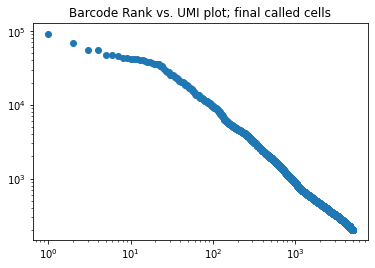

In [93]:
UMI_sums.sort(reverse=True)
plt.figure()
plt.title('Barcode Rank vs. UMI plot; final called cells')
plt.scatter(np.arange(0,len(UMI_sums)),UMI_sums)
plt.xscale('log')
plt.yscale('log')
plt.show()

In [94]:
# woohoo!